<a href="https://colab.research.google.com/github/francisgealon08-stack/lms_activity/blob/main/KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, make_regression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_squared_error


np.random.seed(42)
print("Libraries imported successfully!")

Libraries imported successfully!


KNN Classification (K=1) Accuracy: 0.9600
KNN Classification (K=3) Accuracy: 0.9867
KNN Classification (K=9) Accuracy: 0.9733
KNN Classification (K=15) Accuracy: 0.9600


/tmp/ipykernel_906/1083576963.py:30: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_test_c[:, 0], X_test_c[:, 1], c=y_test_c, marker='x', edgecolor='k', cmap=plt.cm.coolwarm)
/tmp/ipykernel_906/1083576963.py:30: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_test_c[:, 0], X_test_c[:, 1], c=y_test_c, marker='x', edgecolor='k', cmap=plt.cm.coolwarm)
/tmp/ipykernel_906/1083576963.py:30: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_test_c[:, 0], X_test_c[:, 1], c=y_test_c, marker='x', edgecolor='k', cmap=plt.cm.coolwarm)
/

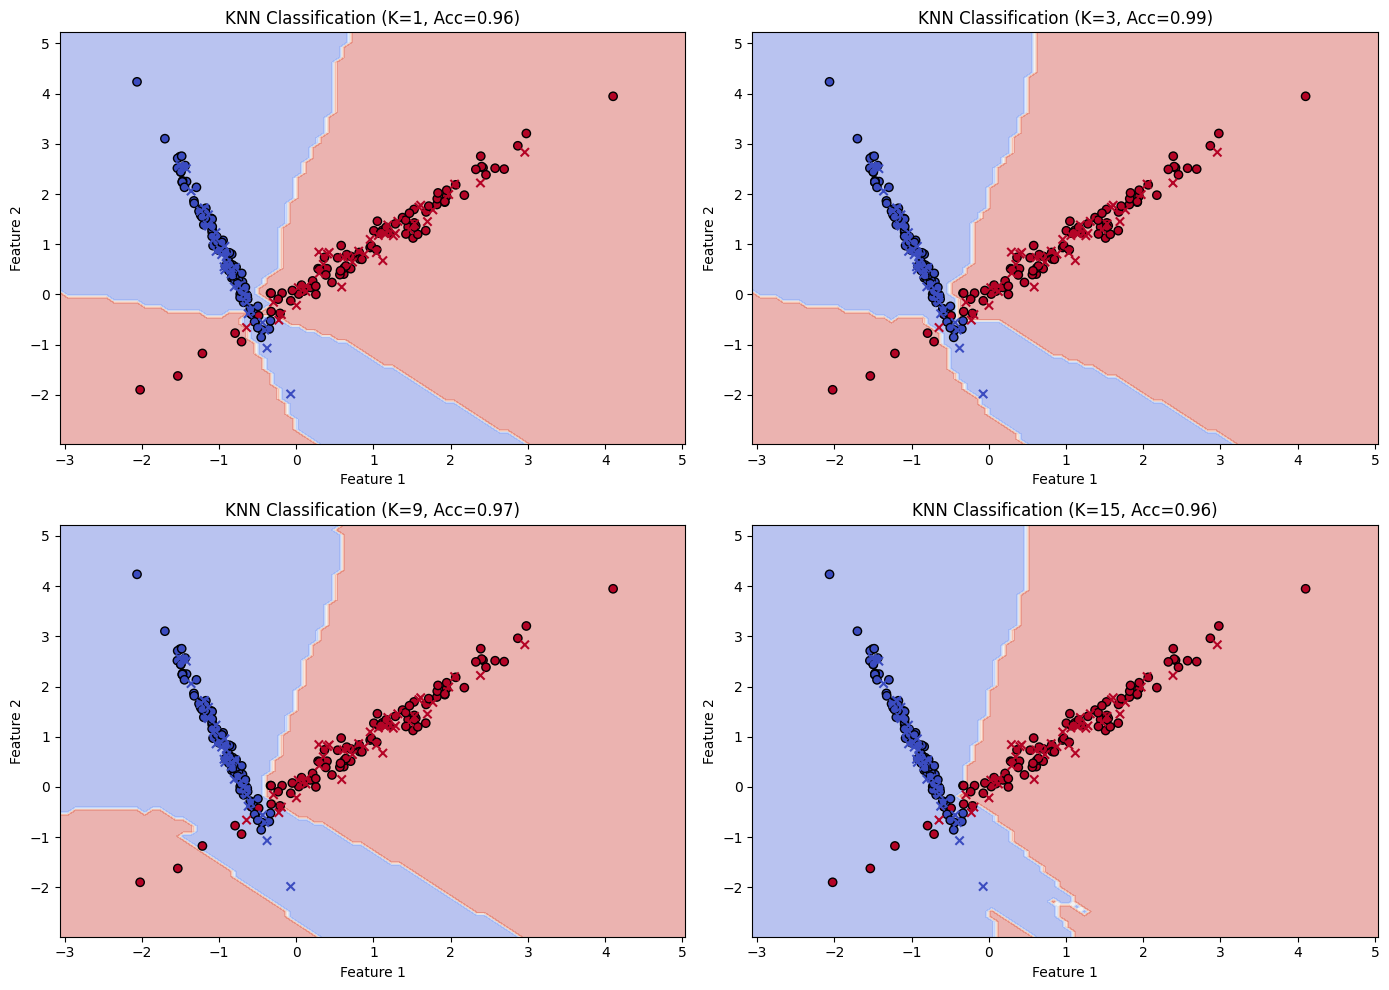

In [ ]:

X_clf, y_clf = make_classification(n_samples=250, n_features=2, n_informative=2,
                                   n_redundant=0, n_clusters_per_class=1, random_state=42)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_clf, y_clf, test_size=0.3, random_state=42)

k_values = [1, 3, 9, 15]
plt.figure(figsize=(14, 10))

for i, k in enumerate(k_values):

    knn_clf = KNeighborsClassifier(n_neighbors=k)
    knn_clf.fit(X_train_c, y_train_c)


    y_pred = knn_clf.predict(X_test_c)
    acc = accuracy_score(y_test_c, y_pred)
    print(f"KNN Classification (K={k}) Accuracy: {acc:.4f}")


    plt.subplot(2, 2, i + 1)
    x_min, x_max = X_clf[:, 0].min() - 1, X_clf[:, 0].max() + 1
    y_min, y_max = X_clf[:, 1].min() - 1, X_clf[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                         np.arange(y_min, y_max, 0.1))
    Z = knn_clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.coolwarm)
    plt.scatter(X_train_c[:, 0], X_train_c[:, 1], c=y_train_c, marker='o', edgecolor='k', cmap=plt.cm.coolwarm)
    plt.scatter(X_test_c[:, 0], X_test_c[:, 1], c=y_test_c, marker='x', edgecolor='k', cmap=plt.cm.coolwarm)
    plt.title(f"KNN Classification (K={k}, Acc={acc:.2f})")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")

plt.tight_layout()
plt.show()

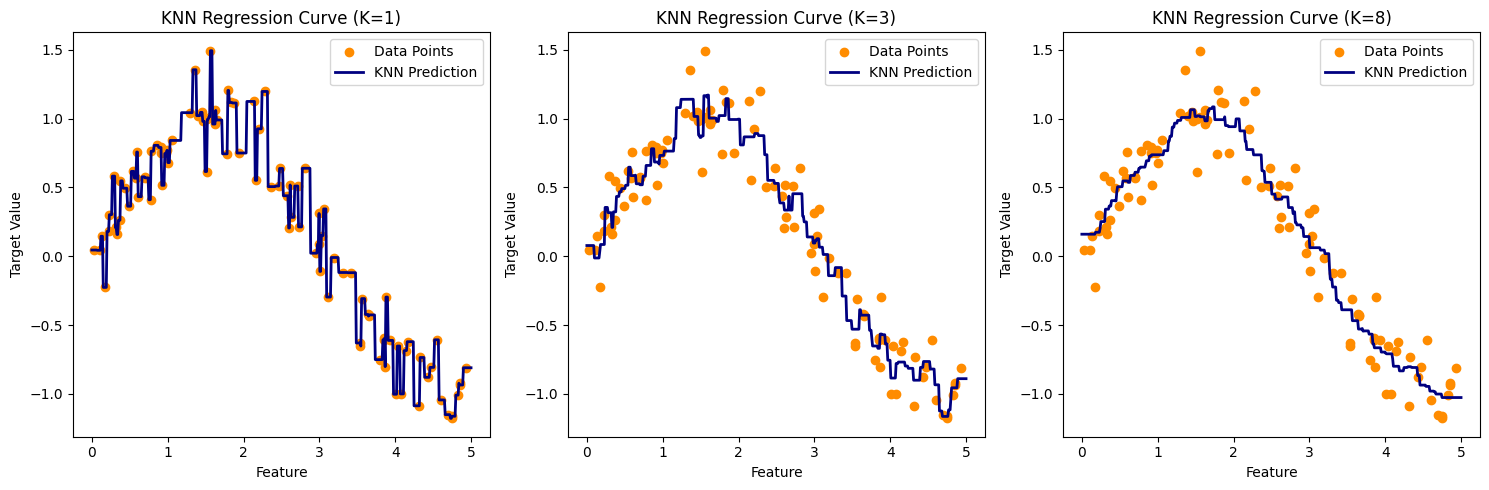

In [ ]:
X_reg = np.sort(5 * np.random.rand(100, 1), axis=0)
y_reg = np.sin(X_reg).ravel() + np.random.normal(0, 0.2, X_reg.shape[0])

k_reg_values = [1, 3, 8]
plt.figure(figsize=(15, 5))

T = np.linspace(0, 5, 500)[:, np.newaxis]

for i, k in enumerate(k_reg_values):
    knn_reg = KNeighborsRegressor(n_neighbors=k)
    knn_reg.fit(X_reg, y_reg)
    y_pred_reg = knn_reg.predict(T)

    plt.subplot(1, len(k_reg_values), i + 1)
    plt.scatter(X_reg, y_reg, color='darkorange', label='Data Points')
    plt.plot(T, y_pred_reg, color='navy', linewidth=2, label='KNN Prediction')
    plt.axis("tight")
    plt.legend()
    plt.title(f"KNN Regression Curve (K={k})")
    plt.xlabel("Feature")
    plt.ylabel("Target Value")

plt.tight_layout()
plt.show()